The main example is from [SHAP Documentation](https://shap-lrjball.readthedocs.io/en/latest/example_notebooks/tree_explainer/NHANES%20I%20Survival%20Model.html) - I added some extra explanations and corrected some outdated code

External inputs are pinned and checked against the repository [asset manifest](../../assets/manifest.json). Run from this checkout; see [download and offline guidance](../../docs/ASSETS.md).

As an extra learning material, I suggest reading [SHAP chapter](https://christophm.github.io/interpretable-ml-book/shap.html) of Interpretable Machine Learning by Christoph Molnar

## NHANES I Survival Model
This is a cox proportional hazards model on data from NHANES I<a name="footnote1-src"></a><sup>[1](#footnote1)</sup> with followup mortality data from the NHANES I Epidemiologic Followup Study. It is designed to illustrate how SHAP values enable the interpretion of XGBoost models with a clarity traditionally only provided by linear models. We see interesting and non-linear patterns in the data, which suggest the potential of this approach. 

The supported XGBoost release in this repository includes Cox loss and SHAP interaction effects. The dataset is downloaded on first use; training and interaction calculations can take several minutes.

---

<a name="footnote1"></a>1. [^](#footnote1-src) In the first National Health and Nutrition Examination Survey (NHANES I), data were collected from a national probability sample of the civilian non-institutionalized population. The NHANES I Epidemiologic Follow-up Study attempts to trace and interview all study subjects at their current location.

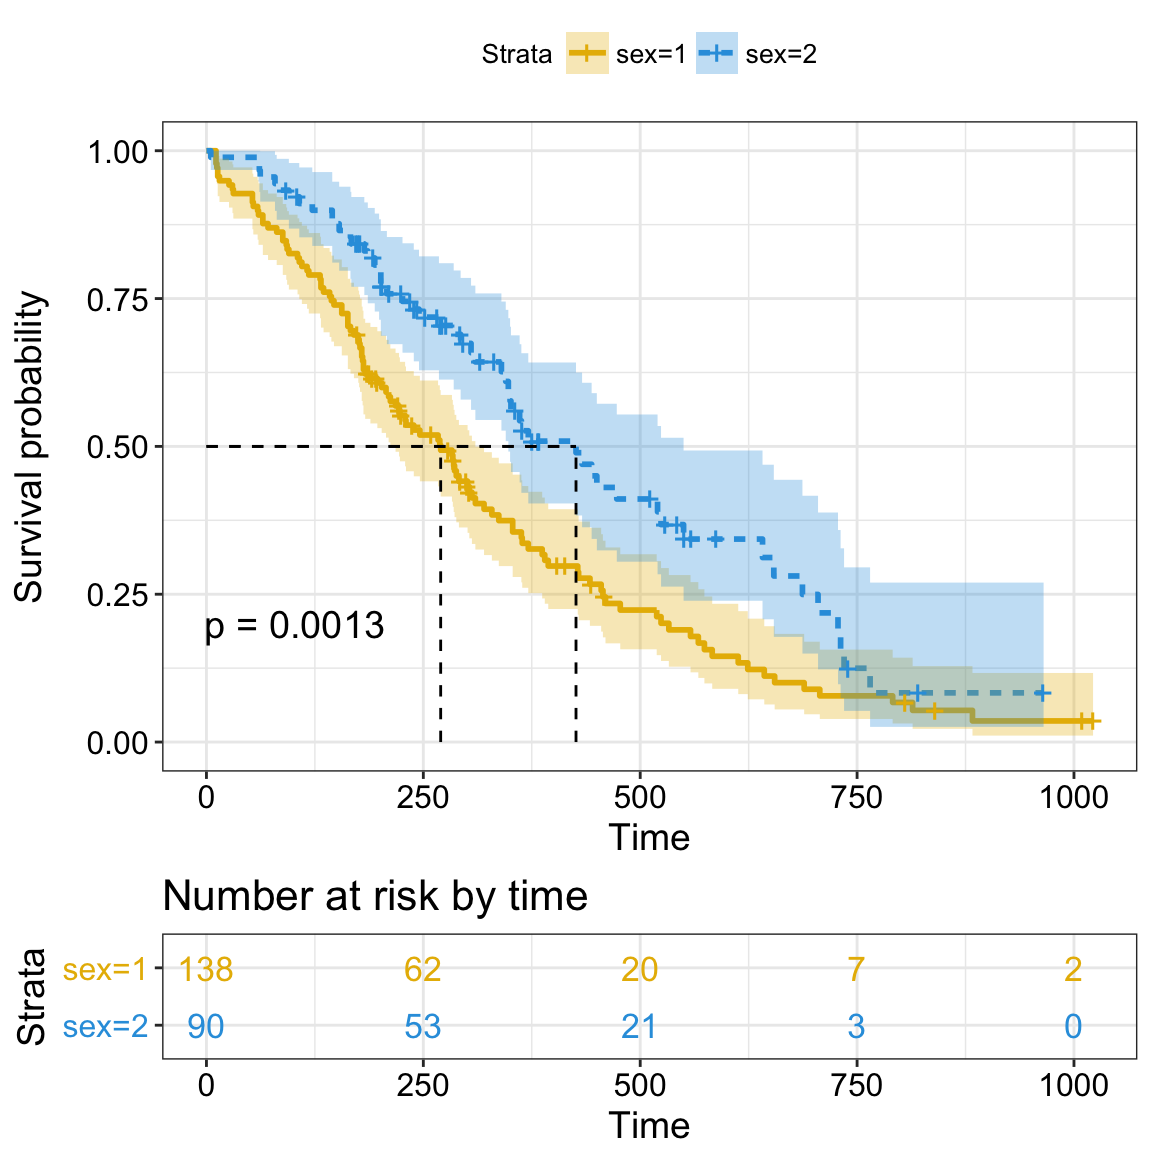

# Survival Analysis

Survival analysis is a statistical field that examines and models the time it takes for events of interest to occur, known as "time-to-event" analysis.

## Key Concepts

### Censored Data
- **Censored Data**: Observations where the event has not occurred at the end of the study or is not observed for other reasons, which is common in survival data.

### Survival Function
- **Survival Function (`S(t)`)**: Represents the probability of surviving past time `t`. It's a key function in survival analysis, showing the likelihood that the event has not occurred by a certain time.

### Hazard Function
- **Hazard Function (`λ(t)`)**: Defines the instantaneous rate at which the event is expected to happen, given no prior occurrence. It essentially reflects the risk of the event occurring at time `t`.

### Kaplan-Meier Estimator
- **Kaplan-Meier Estimator**: A non-parametric method used to estimate the survival function from life table data, accounting for censored data.

### Cox Proportional Hazards Model
- **Cox Proportional Hazards Model**: A regression model used to investigate the effect of multiple variables on survival. It assumes that the effect of the covariates on the hazard is multiplicative and constant over time.

### Life Tables
- **Life Tables**: Tabular compilations of survival statistics that allow for the examination of survival over different intervals.

## Applications

Survival analysis is vital in many fields, including:

- **Medical Research**: For assessing patient survival times and the effectiveness of treatments.
- **Engineering**: In reliability engineering to predict the life duration of materials or systems.
- **Economics**: For analyzing the time until events like job changes, purchases, or other economic behaviors occur.

In [ ]:
from pathlib import Path
import sys
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "assets/manifest.json").is_file())
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))
from xai_assets import asset_file, hf_model_path, verify_dataset, load_nhanesi, load_imagenet50, load_adult_dataframe

import matplotlib.pylab as plt
import numpy as np
import shap
import xgboost
from sklearn.model_selection import train_test_split

## Create XGBoost data objects
This uses a pre-processed subset of NHANES I data available in the SHAP datasets module.

In [ ]:
X, y = load_nhanesi()
X_display, y_display = load_nhanesi(
    display=True)  # human readable feature values

xgb_full = xgboost.DMatrix(X, label=y)

# create a train/test split
X_train, X_test, y_train, y_test = train_test_split(X,
                                                    y,
                                                    test_size=0.2,
                                                    random_state=42)
xgb_train = xgboost.DMatrix(X_train, label=y_train)
xgb_test = xgboost.DMatrix(X_test, label=y_test)

## XGBoost data objects

`DMatrix` stores model inputs and metadata such as labels, sample weights and missing-value indicators. It accepts dense and sparse inputs; missing-value handling is not the same as automatically standardizing or imputing the data. For this Cox objective, positive labels mark observed event times and negative labels mark right-censored times.

## XGBoost survival model

The model combines regression trees using the Cox objective. Its learned risk score can be nonlinear in the features while the proportional-hazards assumption retains a time-independent relative hazard. For missing entries, tree training learns default split directions; this is not an estimated imputed value. Hyperparameters such as depth and regularization affect both predictive behavior and explanations.

In [ ]:
params = {
    "eta": 0.002,
    "max_depth": 3,
    "objective": "survival:cox",
    "subsample": 0.5,
    "seed": 42
}
model_train = xgboost.train(params,
                            xgb_train,
                            10000,
                            evals=[(xgb_test, "test")],
                            verbose_eval=1000)

### Cox negative partial log-likelihood

The reported `cox-nloglik` is the negative Cox partial log-likelihood, based on risk sets at observed event times. Smaller is better for this objective. It is not by itself a calibration score for survival probabilities at a selected time.

In [ ]:
# train final model on the full data set
params = {
    "eta": 0.002,
    "max_depth": 3,
    "objective": "survival:cox",
    "subsample": 0.5,
    "seed": 42
}
model = xgboost.train(params,
                      xgb_full,
                      5000,
                      evals=[(xgb_full, "test")],
                      verbose_eval=1000)

## Prediction scale and proportional hazards

Write the model as $h(t\mid x)=h_0(t)\exp(F(x))$, with scalar margin $F(x)$. XGBoost's default Cox predictions return $\exp(F(x))$; requesting the raw margin returns $F(x)$. The ratio of predicted hazards between two cases is $\exp(F(x_a)-F(x_b))$ under the model.

SHAP below explains the **margin**, so contributions add in log-relative-hazard units. A positive contribution raises that margin relative to the explanation baseline. Neither a margin nor its exponential is a probability of death at a particular time. Obtaining such probabilities also requires a baseline survival estimate and calibration assessment. These are predictive model associations, not treatment effects.

## Check discrimination

Harrell's C-index compares risk order among pairs whose event ordering is observable under right censoring. Larger predicted risk should correspond to an earlier event; ties in risk receive half credit. A score of 1 means perfect ordering of the comparable pairs, not accurate survival probabilities or calibration. This example evaluates a separately trained model on held-out cases before explaining the full-data illustration model.

In [ ]:
def c_statistic_harrell(pred, labels):
    """Harrell's C-index for risk scores and signed Cox time labels.

    Positive labels denote observed events; negative labels denote censoring.
    Higher predictions mean higher risk. Tied risk scores receive half credit.
    """
    pred = np.asarray(pred, dtype=float)
    labels = np.asarray(labels, dtype=float)
    if pred.ndim != 1 or labels.ndim != 1 or pred.shape != labels.shape:
        raise ValueError('pred and labels must be one-dimensional arrays of equal length')
    if not np.all(np.isfinite(pred)) or not np.all(np.isfinite(labels)):
        raise ValueError('pred and labels must contain finite values')
    total = 0
    matches = 0.0
    for j in np.flatnonzero(labels > 0):
        # Compare an observed event with people known to survive longer.
        comparable = np.abs(labels) > labels[j]
        total += np.count_nonzero(comparable)
        matches += np.count_nonzero(pred[j] > pred[comparable])
        matches += 0.5 * np.count_nonzero(pred[j] == pred[comparable])
    if total == 0:
        raise ValueError('No comparable survival pairs')
    return matches / total

In [ ]:
# see how well we can order people by survival
c_statistic_harrell(model_train.predict(xgb_test), y_test)

## Explain the full-data illustration model

The explanations below use the model fitted on the entire dataset, not the separate train/test model used for the discrimination check. They describe that fitted model's behavior on these rows. Use held-out explanations for conclusions about generalization.

## Tree SHAP

TreeExplainer uses tree structure to calculate an additive allocation for the specified model output and reference. Here the default tree-path-dependent reference uses training path counts. Correlated features can receive different allocations under other background definitions. Additivity is a mathematical property of the explanation; it is not a fairness or causal guarantee. [TreeExplainer documentation](https://shap.readthedocs.io/en/latest/generated/shap.TreeExplainer.html).

In [ ]:
shap_values = shap.TreeExplainer(model).shap_values(X)

## SHAP summary plot

The x-axis shows contributions to the XGBoost Cox **margin**, in log-relative-hazard units. The ordering summarizes mean absolute contributions in this dataset; color shows each row's feature value. Inspect the actual plot for ranking and direction instead of treating a fitted association as a clinical risk factor or causal effect. It does not show a probability of death.

In [ ]:
shap.summary_plot(shap_values, X)

## SHAP dependence plots

Each point represents a row. The x-axis is a feature value; the y-axis is its SHAP contribution to the model margin. Color can suggest a second feature to investigate. Vertical dispersion or a color pattern alone does not establish a particular interaction: feature dependence and background definitions can also affect attributions. The later SHAP interaction calculation makes the chosen decomposition explicit.

NHANES I is historical observational data. Its measurements and cohort should not be assumed to match a contemporary clinical population.

In [ ]:
# we pass "Age" instead of an index because dependence_plot() will find it in X's column names for us
# sex_isFemale was automatically chosen for coloring based on a potential interaction to check that
# the interaction is really in the model see SHAP interaction values below
shap.dependence_plot("age", shap_values, X)

In [ ]:
# argument show=False allows us to continue customizing the matplotlib plot before displaying it
shap.dependence_plot("systolic_blood_pressure", shap_values, X, show=False)
plt.xlim(80, 225)
plt.show()

## Compute SHAP interaction values

TreeExplainer returns a symmetric feature-by-feature matrix per row. Diagonal entries are main effects in this decomposition, and off-diagonal entries allocate pair interactions. Each row sums to that feature's SHAP value; the full matrix sums to the output margin minus its baseline. Each pair appears twice, so the sum of the two symmetric entries gives its total allocated interaction. The pair dependence plot combines those entries; the heatmap below displays the matrix entries directly. All values remain in log-relative-hazard units.

In [ ]:
# takes a couple minutes since SHAP interaction values take a factor of 2 * # features
# more time than SHAP values to compute, since this is just an example we only explain
# the first 2,000 people in order to run quicker
shap_interaction_values = shap.TreeExplainer(model).shap_interaction_values(X.iloc[:2000,:])

## SHAP Interaction Value Summary Plot
A summary plot of a SHAP interaction value matrix plots a matrix of summary plots with the main effects on the diagonal and the interaction effects off the diagonal.

In [ ]:
shap.summary_plot(shap_interaction_values, X.iloc[:2000,:])

## SHAP Interaction Value Dependence Plots

In [ ]:
shap.dependence_plot(
    ("age", "age"),
    shap_interaction_values, X.iloc[:2000,:],
    display_features=X_display.iloc[:2000,:]
)

Selecting `("age", "age")` plots the diagonal main-effect entry of the SHAP interaction decomposition against age. It separates the allocated main effect from the off-diagonal pair terms. Inspect the result rather than assuming a perfectly single-valued curve; dependence structure and the decomposition can affect its shape. This is a model attribution, not the causal effect of aging.

The next plot shows the age/sex interaction allocated by this model and SHAP reference. Look for how the contribution varies with age, but do not infer a fixed peak age or a population mortality difference from a previous plot. The vertical axis is an interaction contribution to the margin, not a death-risk probability gap.

In [ ]:
shap.dependence_plot(
    ("age", "sex_isFemale"),
    shap_interaction_values, X.iloc[:2000,:],
    display_features=X_display.iloc[:2000,:]
)

Each point plots one row's allocated age/sex interaction against age, colored by the dataset's `sex_isFemale` indicator. Read the color legend and output scale. Nonzero pair terms indicate an interaction in this SHAP decomposition of the predictor; they do not establish that changing sex or age would cause the displayed effect in a person.

In [ ]:
#Computing the sum of the absolute values of the SHAP
#interaction values across the first axis (rows), which results in
#a measure of the importance of each feature interaction for the
#model's predictions.
tmp = np.abs(shap_interaction_values).sum(0)

#he loop iterates over each feature and zeroes out the diagonal
#of the matrix. This is because the diagonal represents the
#interaction of each feature with itself, which is not relevant
#for off-diagonal interaction effects.
for i in range(tmp.shape[0]):
    tmp[i, i] = 0

# This line finds the indices of the top 7 features with the
#highest summed absolute SHAP interaction values, effectively
#selecting the most important interactions.
inds = np.argsort(-tmp.sum(0))[:7]

# The tmp2 matrix is a subset of the tmp matrix, containing only
#the rows and columns for the top 7 features. This is the data that
#will be visualized in the heatmap.
tmp2 = tmp[inds, :][:, inds]

plt.figure(figsize=(12, 12))

# Displays tmp2 as an image, i.e., a heatmap where the colors
# represent the magnitude of the SHAP interaction values.
plt.imshow(tmp2)

plt.yticks(range(tmp2.shape[0]),
           X.columns[inds],
           rotation=50.4,
           horizontalalignment="right")
plt.xticks(range(tmp2.shape[0]),
           X.columns[inds],
           rotation=50.4,
           horizontalalignment="left")
plt.gca().xaxis.tick_top()
plt.show()

The heatmap sums absolute interaction entries over the first 2000 explained rows, zeroes the diagonal and selects seven features with the largest off-diagonal totals. Its entries aggregate magnitudes, so they lose sign and depend on sample size. They are not individual predictions, probabilities or causal interaction strengths. Compare this summary with the signed per-row plots before drawing conclusions.